# Seminar 8. Constrained Optimality and Discrete Modelling

Checks for the KKT conditions, Lagrangian duality and the first integer models.

## 1. Setup

Every numerical data leaf is compared with an independent calculation.

In [1]:
import copy
import difflib
import io
import itertools
import json
import logging
import math
import re
import zlib
from datetime import date, datetime, time, timedelta, timezone
from decimal import ROUND_HALF_UP, Decimal
from fractions import Fraction as Fr
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.optimize import Bounds, LinearConstraint, linprog, milp, minimize

SEED = 42
TOPIC = "Constrained Optimality and Discrete Modelling"
SEMINAR = "08"
NOTEBOOK = f"{SEMINAR}. {TOPIC}.ipynb"


def find_author_root(start):
    """The folder Seminars/Evgeny Baulin, searched from start upwards."""
    for base in (start, *start.parents):
        for cand in (base, base / "Seminars" / "Evgeny Baulin"):
            if (cand / "checks" / NOTEBOOK).is_file():
                return cand
    raise FileNotFoundError(f"Seminars/Evgeny Baulin/checks/{NOTEBOOK} not found above {start}")


AUTHOR = find_author_root(Path.cwd())
ROOT = AUTHOR.parents[1]
NB_PATH = AUTHOR / "checks" / NOTEBOOK
THEORY = AUTHOR / "theory" / f"{SEMINAR}. {TOPIC}"
CONTENT = THEORY / "content"
FIG_DIR = THEORY / "figures"
WEB = AUTHOR / "web" / SEMINAR
CONTENT_FILES = [WEB / "js" / f"content-{name}.js"
                 for name in ("ui", "main", "problems", "handout", "cheatsheet")]
np.set_printoptions(precision=6, suppress=True)


def strict_loads(text, name):
    """JSON without NaN, Infinity or repeated keys."""
    def pairs(items):
        keys = [k for k, _ in items]
        if len(keys) != len(set(keys)):
            raise ValueError(f"{name}: a repeated key among {keys}")
        return dict(items)

    def constant(value):
        raise ValueError(f"{name}: {value} is not JSON")

    return json.loads(text, object_pairs_hook=pairs, parse_constant=constant)


def strict_json(path):
    return strict_loads(path.read_text(encoding="utf-8"), path.name)


def marked_json(path):
    """The JSON between /*JSON-BEGIN*/ and /*JSON-END*/ of a content file, and the text around it."""
    text = path.read_text(encoding="utf-8")
    m = re.search(r"/\*JSON-BEGIN\*/(.*)/\*JSON-END\*/", text, re.S)
    if m is None:
        raise ValueError(f"{path.name}: no JSON markers")
    return strict_loads(m.group(1), path.name), text[:m.start()] + text[m.end():]


def write_if_changed(path, content):
    """Write text or bytes only when they differ from the file; True when written."""
    content = content.encode("utf-8") if isinstance(content, str) else content
    if path.is_file() and path.read_bytes() == content:
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    return True


PUBLIC = strict_json(CONTENT / "public.json")
PUBLIC["content"] = {k: v for path in CONTENT_FILES for k, v in marked_json(path)[0].items()}
STUDENTS = strict_json(CONTENT / "students.json")
PUB, STU = PUBLIC["data"], STUDENTS["data"]
CHECKS = []
COVERED = set()
MISSING = object()


def short(value, width=40):
    if isinstance(value, np.ndarray):
        value = value.tolist()
    if isinstance(value, (list, tuple)):
        text = "[" + ", ".join(short(v, 10**6) for v in value) + "]"
    elif isinstance(value, dict):
        text = "{" + ", ".join(f"{k}: {short(v, 10**6)}" for k, v in value.items()) + "}"
    elif isinstance(value, (float, np.floating)):
        text = f"{float(value):.10g}"
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


def same(computed, expected, tol):
    if isinstance(expected, np.ndarray):
        expected = expected.tolist()
    if isinstance(expected, bool):
        return isinstance(computed, (bool, np.bool_)) and bool(computed) == expected
    if isinstance(expected, str):
        return isinstance(computed, str) and computed == expected
    if isinstance(expected, dict):
        return (isinstance(computed, dict) and list(computed) == list(expected)
                and all(same(computed[k], expected[k], tol) for k in expected))
    if isinstance(expected, (list, tuple)):
        return (isinstance(computed, (list, tuple, np.ndarray)) and len(computed) == len(expected)
                and all(same(c, e, tol) for c, e in zip(computed, expected)))
    if expected is None or computed is None or isinstance(computed, (bool, np.bool_, str, dict, list)):
        return False
    c, e = float(computed), float(expected)
    return math.isfinite(c) and abs(c - e) <= tol


def check(name, computed, expected, tol=1e-12):
    """Numbers within tol (absolute); strings, booleans, lists and dicts entry by entry."""
    passed = same(computed, expected, tol)
    CHECKS.append({"check": name, "computed": short(computed), "expected": short(expected),
                   "detail": short(computed, 600), "passed": passed})
    return passed


def section(prefix):
    """The checks whose names start with prefix, one line each."""
    rows = [c for c in CHECKS if c["check"].startswith(prefix + ":")]
    if not rows:
        return
    width = max(len(c["check"]) for c in rows)
    for c in rows:
        tail = "ok" if c["passed"] else f"FAILED, expected {c['expected']}"
        print(f"{c['check']:<{width}}  {c['computed']:<40}  {tail}")


def at(root, path):
    """The node at a dotted path, list entries counted from 1."""
    node = root
    for part in path.split("."):
        if isinstance(node, dict) and part in node:
            node = node[part]
        elif isinstance(node, list) and part.isdigit() and 1 <= int(part) <= len(node):
            node = node[int(part) - 1]
        else:
            return MISSING
    return node


def leaves(node, path):
    if isinstance(node, dict):
        for k, v in node.items():
            yield from leaves(v, f"{path}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node, start=1):
            yield from leaves(v, f"{path}.{i}")
    else:
        yield path


def nodes(node):
    if isinstance(node, dict):
        yield node
        for v in node.values():
            yield from nodes(v)
    elif isinstance(node, list):
        for v in node:
            yield from nodes(v)


def lookup(path):
    """(file, node) for a data path that sits in exactly one of the two data sections."""
    found = [(name, at(root, path)) for name, root in (("public", PUB), ("students", STU))]
    found = [(name, node) for name, node in found if node is not MISSING]
    return found[0] if len(found) == 1 else (None, MISSING)


def group(path):
    head, *rest = path.split(".")
    return {"answers": rest[0] if rest else head, "zero": "0", "release": "timeline"}.get(head, head)


def expect(path, computed, tol=1e-9):
    """Compare a computed value with the data leaf at path and mark the leaf as checked."""
    name, expected = lookup(path)
    if expected is MISSING:
        return check(f"{group(path)}: {path} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(expected, path))
    return check(f"{group(path)}: {path}", computed, expected, tol)


def expect_answer(path, computed):
    """Answer spec: the computed value, and a tolerance that takes 4 significant digits but not 1% off."""
    pid, key = path.split(".")
    name, spec = lookup(f"answers.{path}")
    if spec is MISSING:
        return check(f"{pid}: answer {key} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(spec, f"answers.{path}"))
    value, tol = spec.get("value"), spec.get("tol")
    typed = float(f"{float(computed):.4g}")

    def accepted(a):
        return abs(a - value) <= tol * max(1, abs(value))

    check(f"{pid}: answer {key} is a number spec", [sorted(spec), spec.get("type")],
          [["tol", "type", "value"], "number"])
    check(f"{pid}: answer {key} equals the computed value", abs(value - float(computed)), 0.0,
          max(tol, 1e-4 * max(1, abs(float(computed)))))
    check(f"{pid}: answer {key}: the tolerance accepts {typed:g}", accepted(typed), True)
    # When the tolerance is a sizeable fraction of the value, the 1% rejection test is uninformative.
    if abs(value) > 1e-6 and tol < 0.005 * abs(value):
        check(f"{pid}: answer {key}: the tolerance rejects a 1% error",
              not accepted(float(computed) * 1.01) and not accepted(float(computed) * 0.99), True)


print(f"numpy {np.__version__} | matplotlib {matplotlib.__version__} | seed {SEED}")
print(f"notebook: {NB_PATH.relative_to(ROOT)}")
print(f"data leaves: {len(list(leaves(PUB, 'p')))} public, {len(list(leaves(STU, 's')))} students")

numpy 2.5.2 | matplotlib 3.11.1 | seed 42
notebook: Seminars/Evgeny Baulin/checks/08. Constrained Optimality and Discrete Modelling.ipynb
data leaves: 247 public, 113 students


## 2. Helpers

Every active set of a small KKT system is solved exactly; SLSQP gives a numerical cross-check.

In [2]:
def kkt_cases(f, gs, xs):
    """Every active set of a problem with inequalities g_i <= 0: the stationary point with its multipliers,
    and whether it is primal and dual feasible."""
    lams = sp.symbols(f"l1:{len(gs) + 1}", real=True)
    L = f + sum(l * g for l, g in zip(lams, gs))
    rows = []
    for k in range(len(gs) + 1):
        for active in itertools.combinations(range(len(gs)), k):
            eqs = [sp.diff(L, v) for v in xs] + [gs[i] for i in active]
            eqs += [lams[i] for i in range(len(gs)) if i not in active]
            sols = [s for s in sp.solve(eqs, [*xs, *lams], dict=True) if len(s) == len(xs) + len(gs)]
            if not sols:
                rows.append({"active": active, "point": None})
            for s in sols:
                point = [s[v] for v in xs]
                lam = [s[l] for l in lams]
                g_at = [g.subs(s) for g in gs]
                rows.append({"active": active, "point": point, "lam": lam, "g": g_at,
                             "primal": all(v <= 0 for v in g_at), "dual": all(v >= 0 for v in lam)})
    return rows


def survivors(rows):
    return [r for r in rows if r["point"] is not None and r["primal"] and r["dual"]]


def case(rows, active):
    return next(r for r in rows if r["active"] == tuple(active) and r["point"] is not None)


def slsqp(fun, x0, cons):
    res = minimize(fun, x0, method="SLSQP", constraints=cons, options={"ftol": 1e-12, "maxiter": 200})
    return res.x

## 3. The problems

### A1. Two constraints, one active

$\min\,(x-3)^2+2(y-2)^2$ s.t. $x+y\le2$, $y\ge0$; all four active sets.

In [3]:
x, y = sp.symbols("x y", real=True)
P = PUB["A1"]["params"]
(cx, cy), (w1, w2), b = P["center"], P["weights"], P["b"]
f = w1 * (x - cx) ** 2 + w2 * (y - cy) ** 2
gs = [x + y - b, -y]
rows = kkt_cases(f, gs, [x, y])
win = survivors(rows)
check("A1: exactly one active set survives", len(win), 1)
star = win[0]

expect("A1.params", {"center": [cx, cy], "weights": [w1, w2], "b": b})
expect("A1.unc", case(rows, [])["point"])
expect("A1.uncG1", case(rows, [])["g"][0])
expect("A1.only2", case(rows, [1])["point"])
expect("A1.only2G1", case(rows, [1])["g"][0])
expect("A1.both", case(rows, [0, 1])["point"])
expect("A1.bothLam", case(rows, [0, 1])["lam"])
expect("A1.only1", star["point"])
expect("A1.lam", star["lam"])
expect("A1.grad", [sp.diff(f, v).subs({x: star["point"][0], y: star["point"][1]}) for v in (x, y)])
f_star = f.subs({x: star["point"][0], y: star["point"][1]})
expect("A1.f", f_star)
check("A1: the survivor is the active set {1}", star["active"], (0,))

num = slsqp(sp.lambdify([[x, y]], f), [0.0, 0.0],
            [{"type": "ineq", "fun": sp.lambdify([[x, y]], -g)} for g in gs])
check("A1: SLSQP finds the same point", num, [float(v) for v in star["point"]], 1e-6)

expect_answer("A1.x1", star["point"][0])
expect_answer("A1.lam1", star["lam"][0])
expect_answer("A1.f", f_star)
section("A1")

A1: exactly one active set survives                1                                         ok
A1: A1.params                                      {center: [3, 2], weights: [1, 2], b: 2}   ok
A1: A1.unc                                         [3, 2]                                    ok
A1: A1.uncG1                                       3                                         ok
A1: A1.only2                                       [3, 0]                                    ok
A1: A1.only2G1                                     1                                         ok
A1: A1.both                                        [2, 0]                                    ok
A1: A1.bothLam                                     [2, -6]                                   ok
A1: A1.only1                                       [1, 1]                                    ok
A1: A1.lam                                         [4, 0]                                    ok
A1: A1.grad                             

### A2. An active constraint with a zero multiplier

$\min\,3(x-5)^2+(y-2)^2$ s.t. $x\le3.5$, $x+y\le5.5$, $y\ge0$.

In [4]:
P = PUB["A2"]["params"]
(cx, cy), (w1, w2), u, s_ = P["center"], P["weights"], Fr(P["u"]), Fr(P["s"])
f = w1 * (x - cx) ** 2 + w2 * (y - cy) ** 2
gs = [x - sp.Rational(u), x + y - sp.Rational(s_), -y]
rows = kkt_cases(f, gs, [x, y])
win = survivors(rows)
points = {tuple(r["point"]) for r in win}
check("A2: every surviving active set gives the same point", len(points), 1)
star = max(win, key=lambda r: len(r["active"]))
lam = star["lam"]
check("A2: the multiplier is unique (one survivor with both active)", [r["active"] for r in win], [(0,), (0, 1)])
active = [i + 1 for i, g in enumerate(star["g"]) if g == 0]

expect("A2.params", {"center": [cx, cy], "weights": [w1, w2], "u": u, "s": s_})
expect("A2.x", star["point"])
expect("A2.lam", lam)
expect("A2.active", active)
expect("A2.g", star["g"])
f_star = f.subs({x: star["point"][0], y: star["point"][1]})
expect("A2.f", f_star)
check("A2: the second constraint is active with a zero multiplier", [star["g"][1], lam[1]], [0, 0])

num = slsqp(sp.lambdify([[x, y]], f), [0.0, 0.0],
            [{"type": "ineq", "fun": sp.lambdify([[x, y]], -g)} for g in gs])
check("A2: SLSQP finds the same point", num, [float(v) for v in star["point"]], 1e-6)

expect_answer("A2.lam1", lam[0])
expect_answer("A2.lam2", lam[1])
expect_answer("A2.f", f_star)
section("A2")

A2: every surviving active set gives the same point           1                                         ok
A2: the multiplier is unique (one survivor with both active)  [[0], [0, 1]]                             ok
A2: A2.params                                                 {center: [5, 2], weights: [3, 1], u: ...  ok
A2: A2.x                                                      [7/2, 2]                                  ok
A2: A2.lam                                                    [9, 0, 0]                                 ok
A2: A2.active                                                 [1, 2]                                    ok
A2: A2.g                                                      [0, 0, -2]                                ok
A2: A2.f                                                      27/4                                      ok
A2: the second constraint is active with a zero multiplier    [0, 0]                                    ok
A2: SLSQP finds the same point       

### A3. A linear objective on a disk

$\min\,x+2y$ s.t. $x^2+y^2\le45$.

In [5]:
P = PUB["A3"]["params"]
(c1, c2), r2 = P["c"], P["r2"]
f = c1 * x + c2 * y
rows = kkt_cases(f, [x ** 2 + y ** 2 - r2], [x, y])
win = survivors(rows)
check("A3: one KKT point", len(win), 1)
star = win[0]
f_star = f.subs({x: star["point"][0], y: star["point"][1]})

expect("A3.params", {"c": [c1, c2], "r2": r2})
expect("A3.x", star["point"])
expect("A3.lam", star["lam"][0])
expect("A3.f", f_star)
expect("A3.gradNorm2", c1 ** 2 + c2 ** 2)
check("A3: the minimum is -sqrt(r2) |c|", f_star, -sp.sqrt(r2 * (c1 ** 2 + c2 ** 2)))

expect_answer("A3.y", star["point"][1])
expect_answer("A3.lam", star["lam"][0])
expect_answer("A3.f", f_star)
section("A3")

A3: one KKT point                                 1                                         ok
A3: A3.params                                     {c: [1, 2], r2: 45}                       ok
A3: A3.x                                          [-3, -6]                                  ok
A3: A3.lam                                        1/6                                       ok
A3: A3.f                                          -15                                       ok
A3: A3.gradNorm2                                  5                                         ok
A3: the minimum is -sqrt(r2) |c|                  -15                                       ok
A3: answer y is a number spec                     [[tol, type, value], number]              ok
A3: answer y equals the computed value            0                                         ok
A3: answer y: the tolerance accepts -6            True                                      ok
A3: answer y: the tolerance rejects a 1% error    

### B1. The dual of a projection

$\min\,x^2+3y^2$ s.t. $x+y\ge4$; the dual function, strong duality and $p'(b)$.

In [6]:
P = PUB["B1"]["params"]
(w1, w2), b = P["weights"], P["b"]
lam_s, b_s = sp.symbols("lam b", real=True)
L = w1 * x ** 2 + w2 * y ** 2 + lam_s * (b_s - x - y)
argmin = sp.solve([sp.diff(L, x), sp.diff(L, y)], [x, y], dict=True)[0]
q = sp.expand(L.subs(argmin))
lam_star = sp.solve(sp.diff(q, lam_s), lam_s)[0]
d_star = q.subs(lam_s, lam_star)
p_of_b = sp.simplify(d_star)
x_star = [argmin[x].subs(lam_s, lam_star), argmin[y].subs(lam_s, lam_star)]

expect("B1.params", {"weights": [w1, w2], "b": b})
expect("B1.argminCoef", [sp.diff(argmin[x], lam_s), sp.diff(argmin[y], lam_s)])
expect("B1.qCoef", [q.coeff(lam_s, 1).subs(b_s, b), q.coeff(lam_s, 2)])
expect("B1.lam", lam_star.subs(b_s, b))
expect("B1.d", d_star.subs(b_s, b))
expect("B1.x", [v.subs(b_s, b) for v in x_star])
p_primal = (w1 * x ** 2 + w2 * y ** 2).subs({x: x_star[0], y: x_star[1]})
expect("B1.p", p_primal.subs(b_s, b))
expect("B1.pb", sp.simplify(p_of_b / b_s ** 2))
slope = sp.diff(p_of_b, b_s).subs(b_s, b)
expect("B1.slope", slope)
check("B1: strong duality, d* = p*", sp.simplify(d_star - p_primal), 0)
check("B1: the slope of p(b) equals the multiplier", slope - lam_star.subs(b_s, b), 0)
check("B1: Slater holds, the point (b, b) satisfies the constraint strictly", 2 * b > b, True)

expect_answer("B1.lam", lam_star.subs(b_s, b))
expect_answer("B1.d", d_star.subs(b_s, b))
expect_answer("B1.slope", slope)
section("B1")

B1: B1.params                                                         {weights: [1, 3], b: 4}                   ok
B1: B1.argminCoef                                                     [1/2, 1/6]                                ok
B1: B1.qCoef                                                          [4, -1/3]                                 ok
B1: B1.lam                                                            6                                         ok
B1: B1.d                                                              12                                        ok
B1: B1.x                                                              [3, 1]                                    ok
B1: B1.p                                                              12                                        ok
B1: B1.pb                                                             3/4                                       ok
B1: B1.slope                                                          6         

### B2. The multiplier as a price

$\min\,(x-4)^2+(y-3)^2$ s.t. $x+2y\le b$, $b=3$ and $b=3.5$.

In [7]:
P = PUB["B2"]["params"]
c0, a, b, db = [Fr(v) for v in P["center"]], [Fr(v) for v in P["a"]], Fr(P["b"]), Fr(P["db"])


def project(bound):
    """Projection of the centre on a.x <= bound, with the multiplier of the constraint."""
    excess = sum(ai * ci for ai, ci in zip(a, c0)) - bound
    t = max(excess, Fr(0)) / sum(ai * ai for ai in a)
    point = [ci - t * ai for ci, ai in zip(c0, a)]
    return point, 2 * t, sum((pi - ci) ** 2 for pi, ci in zip(point, c0))


pt, lam_b2, p_b2 = project(b)
pt_new, lam_new, p_new = project(b + db)
lam_s = sp.symbols("lam", real=True)
L = (x - c0[0]) ** 2 + (y - c0[1]) ** 2 + lam_s * (a[0] * x + a[1] * y - b)
sol = sp.solve([sp.diff(L, x), sp.diff(L, y)], [x, y], dict=True)[0]
q = sp.expand(L.subs(sol))
q_max = q.subs(lam_s, sp.solve(sp.diff(q, lam_s), lam_s)[0])

expect("B2.params", {"center": c0, "a": a, "b": b, "db": db})
expect("B2.x", pt)
expect("B2.lam", lam_b2)
expect("B2.p", p_b2)
expect("B2.qMax", q_max)
expect("B2.xNew", pt_new)
expect("B2.lamNew", lam_new)
expect("B2.pNew", p_new)
expect("B2.predict", p_b2 - lam_b2 * db)
expect("B2.err", p_new - (p_b2 - lam_b2 * db))
check("B2: strong duality", sp.nsimplify(q_max) - sp.Rational(p_b2.numerator, p_b2.denominator), 0)
h = 1e-6
fd = (float(project(b + Fr(h))[2]) - float(project(b - Fr(h))[2])) / (2 * h)
check("B2: the finite difference of p(b) is -lambda", fd, -float(lam_b2), 1e-6)

expect_answer("B2.lam", lam_b2)
expect_answer("B2.p", p_b2)
expect_answer("B2.pNew", p_new)
section("B2")

B2: B2.params                                      {center: [4, 3], a: [1, 2], b: 3, db:...  ok
B2: B2.x                                           [13/5, 1/5]                               ok
B2: B2.lam                                         14/5                                      ok
B2: B2.p                                           49/5                                      ok
B2: B2.qMax                                        49/5                                      ok
B2: B2.xNew                                        [27/10, 2/5]                              ok
B2: B2.lamNew                                      13/5                                      ok
B2: B2.pNew                                        169/20                                    ok
B2: B2.predict                                     42/5                                      ok
B2: B2.err                                         1/20                                      ok
B2: strong duality                      

### B3. An equality multiplier

$\min\,x^2+2y^2$ s.t. $x+y=6$.

In [8]:
P = PUB["B3"]["params"]
(w1, w2), s_ = P["weights"], P["s"]
nu = sp.symbols("nu", real=True)
L = w1 * x ** 2 + w2 * y ** 2 + nu * (x + y - s_)
sol = sp.solve([sp.diff(L, x), sp.diff(L, y)], [x, y], dict=True)[0]
q = sp.expand(L.subs(sol))
nu_star = sp.solve(sp.diff(q, nu), nu)[0]
x_star = [sol[x].subs(nu, nu_star), sol[y].subs(nu, nu_star)]
p_star = (w1 * x ** 2 + w2 * y ** 2).subs({x: x_star[0], y: x_star[1]})

expect("B3.params", {"weights": [w1, w2], "s": s_})
expect("B3.argminCoef", [sp.diff(sol[x], nu), sp.diff(sol[y], nu)])
expect("B3.qCoef", [q.coeff(nu, 1), q.coeff(nu, 2)])
expect("B3.nu", nu_star)
expect("B3.d", q.subs(nu, nu_star))
expect("B3.x", x_star)
expect("B3.p", p_star)
check("B3: the equality multiplier is negative here", bool(nu_star < 0), True)
num = slsqp(lambda v: w1 * v[0] ** 2 + w2 * v[1] ** 2, [0.0, 0.0],
            [{"type": "eq", "fun": lambda v: v[0] + v[1] - s_}])
check("B3: SLSQP finds the same point", num, [float(v) for v in x_star], 1e-6)

expect_answer("B3.nu", nu_star)
expect_answer("B3.d", q.subs(nu, nu_star))
expect_answer("B3.x", x_star[0])
section("B3")

B3: B3.params                                    {weights: [1, 2], s: 6}                   ok
B3: B3.argminCoef                                [-1/2, -1/4]                              ok
B3: B3.qCoef                                     [-6, -3/8]                                ok
B3: B3.nu                                        -8                                        ok
B3: B3.d                                         24                                        ok
B3: B3.x                                         [4, 2]                                    ok
B3: B3.p                                         24                                        ok
B3: the equality multiplier is negative here     True                                      ok
B3: SLSQP finds the same point                   [4.000000004, 1.999999996]                ok
B3: answer nu is a number spec                   [[tol, type, value], number]              ok
B3: answer nu equals the computed value          0          

### C1. Chairs and tables

$\max\,5x+4y$ s.t. $x+3y\le10$, $4x+y\le13$, $x,y\in\mathbb Z_{\ge0}$.

In [9]:
P = PUB["C1"]["params"]
profit, A, b = P["profit"], P["A"], P["b"]
rows_ = [(A[0], b[0]), (A[1], b[1]), ([-1, 0], 0), ([0, -1], 0)]
verts = []
for (r1, s1), (r2, s2) in itertools.combinations(rows_, 2):
    M = sp.Matrix([r1, r2])
    if M.det() == 0:
        continue
    v = list(M.solve(sp.Matrix([s1, s2])))
    if all(sum(ri * vi for ri, vi in zip(r, v)) <= s for r, s in rows_):
        verts.append(v)
order = [[0, 0], [sp.Rational(b[1], A[1][0]), 0], None, [0, sp.Rational(b[0], A[0][1])]]
inner = [v for v in verts if v[0] > 0 and v[1] > 0]
check("C1: four vertices, one of them inside the quadrant", [len(verts), len(inner)], [4, 1])
order[2] = inner[0]
check("C1: the listed vertices are the vertices of the polygon", sorted(map(tuple, order)), sorted(map(tuple, verts)))
z = lambda v: profit[0] * v[0] + profit[1] * v[1]
lp = linprog([-p for p in profit], A_ub=A, b_ub=b)
pts = [(i, j) for i in range(20) for j in range(20)
       if A[0][0] * i + A[0][1] * j <= b[0] and A[1][0] * i + A[1][1] * j <= b[1]]
best = max(z(p) for p in pts)
ip = [p for p in pts if z(p) == best]
mi = milp([-p for p in profit], constraints=LinearConstraint(A, -np.inf, b), integrality=[1, 1],
          bounds=Bounds(0, np.inf))
rnd = [int(sp.floor(v)) for v in inner[0]]
near = [rnd[0] + 1, rnd[1]]

expect("C1.params", {"profit": profit, "A": A, "b": b})
expect("C1.vertices", order)
expect("C1.zv", [z(v) for v in order])
expect("C1.lp", inner[0])
expect("C1.zlp", z(inner[0]))
check("C1: linprog agrees", [*lp.x, -lp.fun], [float(v) for v in inner[0]] + [float(z(inner[0]))], 1e-9)
expect("C1.round", rnd)
expect("C1.zround", z(rnd))
expect("C1.near", near)
expect("C1.nearRow", A[1][0] * near[0] + A[1][1] * near[1])
check("C1: the nearest rounding up breaks the second row", A[1][0] * near[0] + A[1][1] * near[1] > b[1], True)
expect("C1.ip", list(ip[0]))
expect("C1.zip", best)
check("C1: the integer optimum is unique and milp agrees", [len(ip), *np.round(mi.x).astype(int).tolist()],
      [1, *ip[0]])
expect("C1.gap", z(inner[0]) - best)
expect("C1.count", len(pts))

expect_answer("C1.zlp", z(inner[0]))
expect_answer("C1.zip", best)
expect_answer("C1.xip", ip[0][0])
section("C1")

C1: four vertices, one of them inside the quadrant       [4, 1]                                    ok
C1: the listed vertices are the vertices of the polygon  [[0, 0], [0, 10/3], [29/11, 27/11], [...  ok
C1: C1.params                                            {profit: [5, 4], A: [[1, 3], [4, 1]],...  ok
C1: C1.vertices                                          [[0, 0], [13/4, 0], [29/11, 27/11], [...  ok
C1: C1.zv                                                [0, 65/4, 23, 40/3]                       ok
C1: C1.lp                                                [29/11, 27/11]                            ok
C1: C1.zlp                                               23                                        ok
C1: linprog agrees                                       [2.636363636, 2.454545455, 23]            ok
C1: C1.round                                             [2, 2]                                    ok
C1: C1.zround                                            18                       

### C2. Fixed charge and Big-M

Two machines with fixed costs, demand 7; the relaxation with $M=u$ and $M=10u$.

In [10]:
P = PUB["C2"]["params"]
D, Fc, cc, uc, scale = P["D"], P["F"], P["c"], P["u"], P["scale"]


def plan_cost(open_):
    """Cheapest plan with the given machines open, or None when their capacity is short."""
    if sum(u for u, o in zip(uc, open_) if o) < D:
        return None, None
    left, x_ = D, [0, 0]
    for i in sorted([i for i in range(2) if open_[i]], key=lambda i: cc[i]):
        x_[i] = min(uc[i], left)
        left -= x_[i]
    return sum(Fc[i] * open_[i] + cc[i] * x_[i] for i in range(2)), x_


costs = {o: plan_cost(o) for o in itertools.product([0, 1], repeat=2)}
ip_c2 = min(c for c, _ in costs.values() if c is not None)


def relaxation(M):
    """LP relaxation: variables x1, x2, z1, z2 with x_i <= u_i, x_i <= M_i z_i, 0 <= z_i <= 1."""
    cost = [cc[0], cc[1], Fc[0], Fc[1]]
    A_ub = [[1, 0, -M[0], 0], [0, 1, 0, -M[1]]]
    res = linprog(cost, A_ub=A_ub, b_ub=[0, 0], A_eq=[[1, 1, 0, 0]], b_eq=[D],
                  bounds=[(0, uc[0]), (0, uc[1]), (0, 1), (0, 1)])
    return res.fun


def greedy(eff):
    left, total = D, Fr(0)
    for i in sorted(range(2), key=lambda i: eff[i]):
        take = min(uc[i], left)
        total += take * eff[i]
        left -= take
    return total


eff_u = [cc[i] + Fr(Fc[i], uc[i]) for i in range(2)]
eff_big = [cc[i] + Fr(Fc[i], scale * uc[i]) for i in range(2)]
mi = milp([cc[0], cc[1], Fc[0], Fc[1]],
          constraints=[LinearConstraint([[1, 1, 0, 0]], D, D),
                       LinearConstraint([[1, 0, -uc[0], 0], [0, 1, 0, -uc[1]]], -np.inf, 0)],
          integrality=[0, 0, 1, 1], bounds=Bounds([0, 0, 0, 0], [uc[0], uc[1], 1, 1]))

expect("C2.params", {"D": D, "F": Fc, "c": cc, "u": uc, "scale": scale})
expect("C2.m1Cap", uc[0])
check("C2: machine 1 alone is short of the demand", costs[(1, 0)][0] is None, True)
expect("C2.costM2", costs[(0, 1)][0])
expect("C2.costBoth", costs[(1, 1)][0])
expect("C2.xBoth", costs[(1, 1)][1])
expect("C2.ip", ip_c2)
check("C2: milp agrees", mi.fun, ip_c2, 1e-9)
expect("C2.effU", eff_u)
expect("C2.lpU", greedy(eff_u))
check("C2: linprog with M = u agrees", relaxation(uc), float(greedy(eff_u)), 1e-9)
expect("C2.effBig", eff_big)
expect("C2.lpBig", greedy(eff_big))
check("C2: linprog with M = scale u agrees", relaxation([scale * u for u in uc]), float(greedy(eff_big)), 1e-9)

expect_answer("C2.ip", ip_c2)
expect_answer("C2.lpU", greedy(eff_u))
expect_answer("C2.lpBig", greedy(eff_big))
section("C2")

C2: C2.params                                       {D: 7, F: [20, 6], c: [2, 5], u: [5, ...  ok
C2: C2.m1Cap                                        5                                         ok
C2: machine 1 alone is short of the demand          True                                      ok
C2: C2.costM2                                       41                                        ok
C2: C2.costBoth                                     46                                        ok
C2: C2.xBoth                                        [5, 2]                                    ok
C2: C2.ip                                           41                                        ok
C2: milp agrees                                     41                                        ok
C2: C2.effU                                         [6, 23/4]                                 ok
C2: C2.lpU                                          161/4                                     ok
C2: linprog with M = u agrees 

### C3. A knapsack and its relaxation

Four items, capacity 9; the ratio rule against the integer optimum.

In [11]:
P = PUB["C3"]["params"]
vals, wts, cap = P["values"], P["weights"], P["cap"]
order = sorted(range(len(vals)), key=lambda i: -Fr(vals[i], wts[i]))
left, lp_c3, prefix, frac = cap, Fr(0), [], None
for i in order:
    if wts[i] <= left:
        left -= wts[i]
        lp_c3 += vals[i]
        prefix.append(i)
    else:
        frac = Fr(left, wts[i])
        lp_c3 += frac * vals[i]
        break
subsets = [s for k in range(len(vals) + 1) for s in itertools.combinations(range(len(vals)), k)
           if sum(wts[i] for i in s) <= cap]
best = max(sum(vals[i] for i in s) for s in subsets)
opt = [s for s in subsets if sum(vals[i] for i in s) == best]
lp = linprog([-v for v in vals], A_ub=[wts], b_ub=[cap], bounds=[(0, 1)] * len(vals))

expect("C3.params", {"values": vals, "weights": wts, "cap": cap})
expect("C3.order", [i + 1 for i in order])
expect("C3.lp", lp_c3)
check("C3: linprog agrees with the ratio rule", -lp.fun, float(lp_c3), 1e-9)
expect("C3.lpFrac", frac)
expect("C3.ip", best)
check("C3: the integer optimum is unique", len(opt), 1)
expect("C3.set", [i + 1 for i in opt[0]])
expect("C3.gap", lp_c3 - best)
expect("C3.greedy", sum(vals[i] for i in prefix))
check("C3: rounding the LP down is not optimal", sum(vals[i] for i in prefix) < best, True)

expect_answer("C3.lp", lp_c3)
expect_answer("C3.ip", best)
expect_answer("C3.k", len(opt[0]))
section("C3")

C3: C3.params                                    {values: [8, 6, 5, 4], weights: [3, 5...  ok
C3: C3.order                                     [1, 3, 2, 4]                              ok
C3: C3.lp                                        89/5                                      ok
C3: linprog agrees with the ratio rule           17.8                                      ok
C3: C3.lpFrac                                    4/5                                       ok
C3: C3.ip                                        14                                        ok
C3: the integer optimum is unique                1                                         ok
C3: C3.set                                       [1, 2]                                    ok
C3: C3.gap                                       19/5                                      ok
C3: C3.greedy                                    13                                        ok
C3: rounding the LP down is not optimal          True       

## 4. Exit ticket and block D

In [12]:
E = PUB["exit"]
expect("exit.lam", Fr(E["lam"]).limit_denominator(100))
expect("exit.db", Fr(E["db"]).limit_denominator(100))
expect("exit.change", -Fr(E["lam"]).limit_denominator(100) * Fr(E["db"]).limit_denominator(100))
expect("exit.lp", Fr(E["lp"]).limit_denominator(100))
expect("exit.inc", int(E["inc"]))
gap_abs = int(E["inc"]) - Fr(E["lp"]).limit_denominator(100)
expect("exit.gapAbs", gap_abs)
expect("exit.gapRel", gap_abs / int(E["inc"]))

# D1: min x s.t. x^2 <= 0; q(lam) = -1/(4 lam) for lam > 0, its supremum 0 is not attained
lam_s, x_s = sp.symbols("lam", positive=True), sp.symbols("t", real=True)
q1 = sp.simplify((x_s + lam_s * x_s ** 2).subs(x_s, sp.solve(sp.diff(x_s + lam_s * x_s ** 2, x_s), x_s)[0]))
check("demo: D1 dual function", sp.simplify(q1 + 1 / (4 * lam_s)), 0)
check("demo: D1 the supremum is the limit at infinity", sp.limit(q1, lam_s, sp.oo), 0)

# D2: Lagrangian dual of a knapsack; its minimum sits at a ratio v_i / w_i
G = PUB["demo"]["gap"]
v, w, capk = G["values"], G["weights"], G["cap"]
qk = lambda l: l * capk + sum(max(Fr(0), vi - l * wi) for vi, wi in zip(v, w))
breaks = [Fr(0)] + [Fr(vi, wi) for vi, wi in zip(v, w)]
lam_k = min(breaks, key=qk)
ipk = max(sum(v[i] for i in s) for k in range(len(v) + 1) for s in itertools.combinations(range(len(v)), k)
          if sum(w[i] for i in s) <= capk)
lpk = linprog([-vi for vi in v], A_ub=[w], b_ub=[capk], bounds=[(0, 1)] * len(v))
grid = np.linspace(0, 4, 4001)
check("demo: D2 the breakpoint minimum is the grid minimum",
      float(qk(lam_k)), min(float(qk(Fr(float(t)).limit_denominator(1000))) for t in grid), 1e-9)
check("demo: D2 the dual bound equals the LP bound", float(qk(lam_k)), -lpk.fun, 1e-9)
expect("demo.gap", {"values": v, "weights": w, "cap": capk, "ip": ipk, "dual": qk(lam_k), "lam": lam_k})

# D3: rounding the LP optimum of max y s.t. 2y - 2x <= 1, 2y + 2x <= 7
Ar, br = [[-2, 2], [2, 2]], [1, 7]
lp_r = linprog([0, -1], A_ub=Ar, b_ub=br, bounds=[(None, None), (0, None)])
ok = lambda p: all(r[0] * p[0] + r[1] * p[1] <= s for r, s in zip(Ar, br)) and p[1] >= 0
y_ip = max(j for i in range(-5, 6) for j in range(0, 6) if ok((i, j)))
rounded = [[1, 2], [2, 2]]
check("demo: D3 the rounded points are infeasible", [ok(p) for p in rounded], [False, False])
expect("demo.round", {"lp": lp_r.x.tolist(),
                      "ylp": -lp_r.fun, "yip": y_ip, "rounded": rounded})

# D4: open a facility (fixed F, unit c, capacity u, x <= M z) or buy outside at price p
B = PUB["demo"]["bigm"]
Fb, cb, pb, ub, Db, Ms = B["F"], B["c"], B["p"], B["u"], B["D"], B["Ms"]
bounds_ = []
for Mv in Ms:
    res = linprog([cb, pb, Fb], A_ub=[[1, 0, -Mv]], b_ub=[0], A_eq=[[1, 1, 0]], b_eq=[Db],
                  bounds=[(0, ub), (0, None), (0, 1)])
    bounds_.append(Fr(res.fun).limit_denominator(1000))
    check(f"demo: D4 the bound at M = {Mv} has the closed form", res.fun,
          float(Db * min(Fr(pb), cb + Fr(Fb, Mv))), 1e-9)
ip_b = min(Fb + cb * Db if Db <= ub else None, pb * Db)
expect("demo.bigm", {"F": Fb, "c": cb, "p": pb, "u": ub, "D": Db, "Ms": Ms, "bounds": bounds_, "ip": ip_b,
                     "floor": cb * Db})
check("demo: D4 at M = u the relaxation is exact", bounds_[0], ip_b)
section("exit")
section("demo")

exit: exit.lam     3/2                                       ok
exit: exit.db      1/5                                       ok
exit: exit.change  -3/10                                     ok
exit: exit.lp      35/2                                      ok
exit: exit.inc     19                                        ok
exit: exit.gapAbs  3/2                                       ok
exit: exit.gapRel  3/38                                      ok
demo: D1 dual function                               0                                         ok
demo: D1 the supremum is the limit at infinity       0                                         ok
demo: D2 the breakpoint minimum is the grid minimum  13.5                                      ok
demo: D2 the dual bound equals the LP bound          13.5                                      ok
demo: demo.gap                                       {values: [10, 7, 4], weights: [5, 4, ...  ok
demo: D3 the rounded points are infeasible           [False, F

## 5. Release and timeline

Start at 13:00 Moscow time; the planned lengths add up to the end of the class at 14:20.

In [13]:
PLAN = {
    "0": [("recap", 6)],
    "A": [("recap", 2), ("P1", 6), ("P23", 7), ("review", 3)],
    "B": [("recap", 2), ("P1", 6), ("P23", 7), ("review", 3)],
    "C": [("recap", 2), ("P1", 6), ("P23", 7), ("review", 3)],
    "D": [("D1", Fr(5, 2)), ("D2", Fr(5, 2)), ("D3", Fr(5, 2)), ("D4", Fr(5, 2))],
    "E": [("summary", 2), ("exit", 2), ("home", 1)],
}
START = 13 * 60


def mmss(minutes):
    seconds = int(minutes * 60)
    return f"{seconds // 60}:{seconds % 60:02d}"


def clock_str(minutes):
    minute = START + int(minutes)
    return f"{minute // 60}:{minute % 60:02d}"


timeline = {"blocks": list(PLAN), "sec": {}, "start": {}, "clock": {}}
elapsed = 0
for block, parts in PLAN.items():
    total = sum(m for _, m in parts)
    timeline[block] = {key: mmss(m) for key, m in parts}
    timeline[block]["total"] = mmss(total)
    timeline["sec"][block] = {key: int(m * 60) for key, m in parts}
    timeline["start"][block] = mmss(elapsed)
    timeline["clock"][block] = clock_str(elapsed)
    elapsed += total

timeline["buffer"] = mmss(5)
timeline["sec"]["buffer"] = 300
timeline["start"]["buffer"] = mmss(elapsed)
timeline["clock"]["buffer"] = clock_str(elapsed)
timeline["total"] = mmss(elapsed + 5)
timeline["clock"]["end"] = clock_str(elapsed + 5)
expect("timeline", timeline)
check("timeline: the class lasts 80 minutes with the buffer", elapsed + 5, 80)

MONTHS_RU = ["января", "февраля", "марта", "апреля", "мая", "июня", "июля", "августа", "сентября",
             "октября", "ноября", "декабря"]
day = date(2026, 11, 2)
release = datetime.combine(day, time(14, 20), timezone(timedelta(hours=3)))
expect("release.iso", release.isoformat())
expect("release.day", f"{day.day} {day.strftime('%B')}")
expect("release.dayRu", f"{day.day} {MONTHS_RU[day.month - 1]}")
check("timeline: release is on Monday", day.weekday(), 0)
check("timeline: the class ends at the release time", timeline["clock"]["end"], release.strftime("%H:%M"))
check("timeline: config matches the release",
      re.findall(r"unlockAt:\s*'([^']*)'", (WEB / "js/config.js").read_text()), [release.isoformat()])
section("timeline")

all_leaves = [(name, p) for name, data in [("public", PUB), ("students", STU)]
              for key, value in data.items() for p in leaves(value, key)]
check("coverage: every data leaf has an independent calculation", sorted(set(all_leaves) - COVERED), [])
print(f"{len(COVERED)} data leaves checked")

timeline: timeline                                    {blocks: [0, A, B, C, D, E], sec: {0:...  ok
timeline: the class lasts 80 minutes with the buffer  80                                        ok
timeline: release.iso                                 2026-11-02T14:20:00+03:00                 ok
timeline: release.day                                 2 November                                ok
timeline: release.dayRu                               2 ноября                                  ok
timeline: release is on Monday                        0                                         ok
timeline: the class ends at the release time          14:20                                     ok
timeline: config matches the release                  [2026-11-02T14:20:00+03:00]               ok
360 data leaves checked


## 6. Figures

Two board figures (A1, C1) and two for block D: the knapsack dual and the relaxation as $M$ grows.

In [14]:
failed = [c["check"] for c in CHECKS if not c["passed"]]
assert not failed, f"figures refused, failed checks: {failed}"

logging.getLogger("fontTools").setLevel(logging.ERROR)

HSE = {
    "blue": "#102D69",
    "accent": "#C62828",
    "gray": "#6C727E",
    "orange": "#C96A00",
    "light": "#EBEFF6",
    "fill": "#C9D6EA",
    "fill2": "#F3D4D4",
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.edgecolor": HSE["gray"],
    "axes.linewidth": 0.8,
    "xtick.color": HSE["gray"],
    "ytick.color": HSE["gray"],
    "svg.hashsalt": "seminar08",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})
FIGURES = []
PUBLIC_FIGURES = {d["src"] for d in nodes(PUBLIC["content"]) if isinstance(d.get("src"), str)}
SERIF = "font-family: 'STIXGeneral', 'STIX Two Text', 'Times New Roman', Times, serif"


def save(fig, name):
    """Write name.svg and name.pdf for the handout, and name.svg for a public figure."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="svg", bbox_inches="tight", metadata={"Date": None})
    svg = re.sub(r"font-family: 'STIXGeneral'(, serif)?(?=[;\"])", SERIF, buffer.getvalue().decode("utf-8"))
    buffer = io.BytesIO()
    fig.savefig(buffer, format="pdf", bbox_inches="tight", metadata={"CreationDate": None, "ModDate": None})
    targets = {FIG_DIR / f"{name}.svg": svg.encode("utf-8"), FIG_DIR / f"{name}.pdf": buffer.getvalue()}
    if name in PUBLIC_FIGURES:
        targets[WEB / "figures" / f"{name}.svg"] = svg.encode("utf-8")
    for path, content in targets.items():
        write_if_changed(path, content)
    words = [t.get_text() for t in fig.findobj(matplotlib.text.Text)
             if re.search("[A-Za-z]", re.sub(r"\$[^$]*\$", "", t.get_text()))]
    check(f"figures: {name} has no words outside formulas", words, [])
    if name not in FIGURES:
        FIGURES.append(name)

### fig_a1: the KKT point of A1

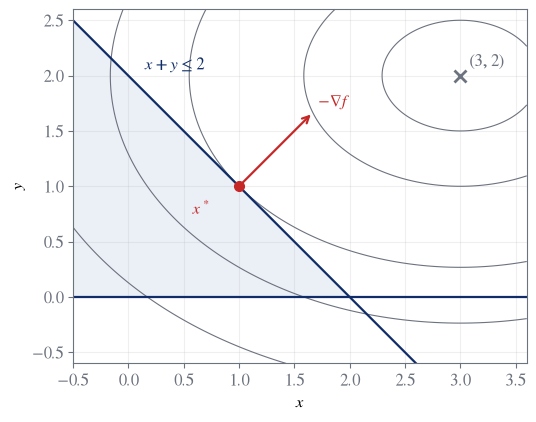

In [15]:
a1 = PUB["A1"]
cx, cy = a1["params"]["center"]
w1, w2 = a1["params"]["weights"]
bb = a1["params"]["b"]
xs, ys = np.meshgrid(np.linspace(-0.5, 3.6, 300), np.linspace(-0.6, 2.6, 300))
fv = w1 * (xs - cx) ** 2 + w2 * (ys - cy) ** 2
fig, ax = plt.subplots(figsize=(6.0, 4.6))
ax.fill([-0.5, bb, -0.5], [0, 0, bb + 0.5], color=HSE["light"], zorder=0)
ax.contour(xs, ys, fv, levels=[0.5, 2, a1["f"], 10, 16], colors=HSE["gray"], linewidths=0.8)
t = np.linspace(-0.5, 2.6, 2)
ax.plot(t, bb - t, color=HSE["blue"], lw=1.6)
ax.axhline(0, color=HSE["blue"], lw=1.6)
xst = a1["only1"]
g = np.array(a1["grad"], float)
ax.plot(*xst, "o", color=HSE["accent"], ms=7, zorder=5)
ax.plot(cx, cy, "x", color=HSE["gray"], ms=8, mew=2)
ax.annotate("", xy=(xst[0] - g[0] / 6, xst[1] - g[1] / 6), xytext=tuple(xst),
            arrowprops=dict(arrowstyle="->", color=HSE["accent"], lw=1.6))
ax.text(xst[0] - 0.42, xst[1] - 0.25, r"$x^*$", color=HSE["accent"])
ax.text(xst[0] - g[0] / 6 + 0.05, xst[1] - g[1] / 6 + 0.05, r"$-\nabla f$", color=HSE["accent"])
ax.text(cx + 0.08, cy + 0.08, rf"$({cx},{cy})$", color=HSE["gray"])
ax.text(0.15, 2.05, r"$x+y\leq 2$", color=HSE["blue"])
ax.set(xlim=(-0.5, 3.6), ylim=(-0.6, 2.6), xlabel=r"$x$", ylabel=r"$y$", aspect="equal")
ax.grid(alpha=0.2)
save(fig, "fig_a1")
plt.show()

### fig_c1: integer points and the LP polygon of C1

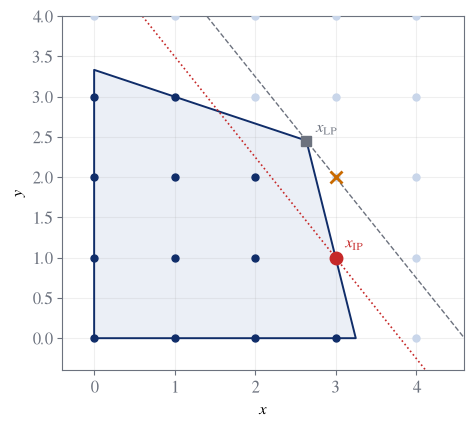

In [16]:
c1 = PUB["C1"]
(a11, a12), (a21, a22) = c1["params"]["A"]
b1, b2 = c1["params"]["b"]
fig, ax = plt.subplots(figsize=(6.0, 4.6))
V = np.array(c1["vertices"])
ax.fill(V[:, 0], V[:, 1], color=HSE["light"], zorder=0)
ax.plot(np.append(V[:, 0], V[0, 0]), np.append(V[:, 1], V[0, 1]), color=HSE["blue"], lw=1.4)
for i in range(6):
    for j in range(5):
        ok = a11 * i + a12 * j <= b1 and a21 * i + a22 * j <= b2
        ax.plot(i, j, "o", ms=5, color=HSE["blue"] if ok else HSE["fill"], zorder=3)
p1, p2 = c1["params"]["profit"]
t = np.linspace(-0.5, 5.5, 2)
ax.plot(t, (c1["zlp"] - p1 * t) / p2, "--", color=HSE["gray"], lw=1.0)
ax.plot(t, (c1["zip"] - p1 * t) / p2, ":", color=HSE["accent"], lw=1.2)
ax.plot(*c1["lp"], "s", color=HSE["gray"], ms=7, zorder=4)
ax.plot(*c1["ip"], "o", color=HSE["accent"], ms=9, zorder=5)
ax.plot(*c1["near"], "x", color=HSE["orange"], ms=9, mew=2, zorder=5)
ax.text(c1["lp"][0] + 0.12, c1["lp"][1] + 0.1, r"$x_{\mathrm{LP}}$", color=HSE["gray"])
ax.text(c1["ip"][0] + 0.12, c1["ip"][1] + 0.12, r"$x_{\mathrm{IP}}$", color=HSE["accent"])
ax.set(xlim=(-0.4, 4.6), ylim=(-0.4, 4.0), xlabel=r"$x$", ylabel=r"$y$", aspect="equal")
ax.grid(alpha=0.2)
save(fig, "fig_c1")
plt.show()

### fig_gap: the Lagrangian dual of a knapsack

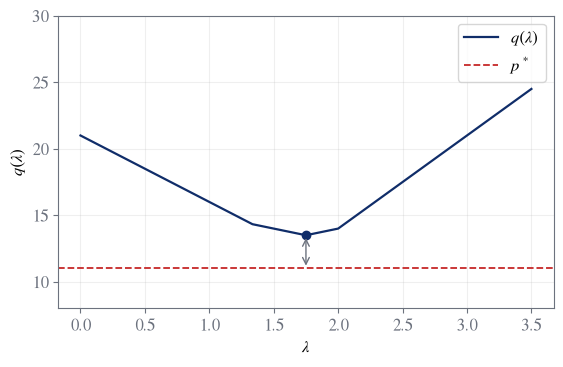

In [17]:
gp = PUB["demo"]["gap"]
lam = np.linspace(0, 3.5, 701)
q = lam * gp["cap"] + sum(np.maximum(0, v - lam * w) for v, w in zip(gp["values"], gp["weights"]))
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(lam, q, color=HSE["blue"], lw=1.6, label=r"$q(\lambda)$")
ax.axhline(gp["ip"], color=HSE["accent"], lw=1.3, ls="--", label=r"$p^*$")
ax.plot(gp["lam"], gp["dual"], "o", color=HSE["blue"], ms=6)
ax.annotate("", xy=(gp["lam"], gp["ip"]), xytext=(gp["lam"], gp["dual"]),
            arrowprops=dict(arrowstyle="<->", color=HSE["gray"], lw=1.0))
ax.set(xlabel=r"$\lambda$", ylabel=r"$q(\lambda)$", ylim=(gp["ip"] - 3, 30))
ax.legend(loc="upper right")
ax.grid(alpha=0.2)
save(fig, "fig_gap")
plt.show()

### fig_bigm: the relaxation bound against M

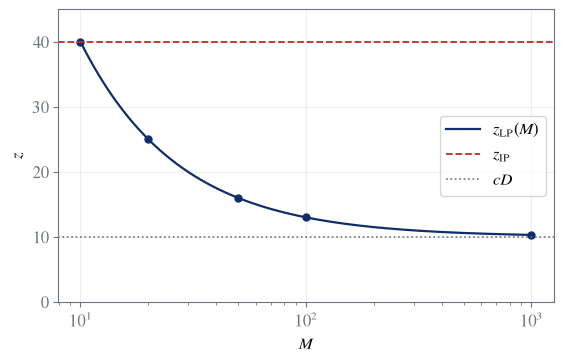

In [18]:
bm = PUB["demo"]["bigm"]
M = np.geomspace(bm["u"], 1000, 300)
bound = bm["D"] * np.minimum(bm["p"], bm["c"] + bm["F"] / M)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(M, bound, color=HSE["blue"], lw=1.6, label=r"$z_{\mathrm{LP}}(M)$")
ax.plot(bm["Ms"], bm["bounds"], "o", color=HSE["blue"], ms=5)
ax.axhline(bm["ip"], color=HSE["accent"], ls="--", lw=1.3, label=r"$z_{\mathrm{IP}}$")
ax.axhline(bm["floor"], color=HSE["gray"], ls=":", lw=1.2, label=r"$cD$")
ax.set_xscale("log")
ax.set(xlabel=r"$M$", ylabel=r"$z$", ylim=(0, bm["ip"] + 5))
ax.legend(loc="center right")
ax.grid(alpha=0.2)
save(fig, "fig_bigm")
plt.show()

## 7. Handout and cheat sheet

LaTeX for both languages is built from the content files; the token substitutions and the formatting follow render.js so the printed numbers equal those on the page.

In [19]:
TOKEN = re.compile(r"\{\{\s*([A-Za-z0-9.]+)\s*\}\}")


def merge_over(target, overlay):
    """The merge of access.js: objects key by key, arrays element by element, anything else replaced."""
    for key, b in overlay.items():
        a = target.get(key)
        if isinstance(a, dict) and isinstance(b, dict):
            merge_over(a, b)
        elif isinstance(a, list) and isinstance(b, list):
            for i, item in enumerate(b):
                if i < len(a) and isinstance(a[i], dict) and isinstance(item, dict):
                    merge_over(a[i], item)
                elif i < len(a):
                    a[i] = copy.deepcopy(item)
                else:
                    a.append(copy.deepcopy(item))
        else:
            target[key] = copy.deepcopy(b)
    return target


def value_at(data, path):
    node = at(data, path)
    if node is MISSING or node is None or isinstance(node, dict):
        raise KeyError(f"unresolved token {path}")
    return node


def is_num(v):
    return isinstance(v, (int, float)) and not isinstance(v, bool)


def decimal_str(v, digits=4):
    s = str(Decimal(v).quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))
    if "." in s:
        s = s.rstrip("0").rstrip(".")
    return "0" if s == "-0" else s


def tex_num(v, lang, math):
    s = decimal_str(v)
    if math:
        return s.replace(".", "{,}") if lang == "ru" else s
    s = s.replace(".", ",") if lang == "ru" else s
    return "−" + s[1:] if s.startswith("-") else s


def tex_value(v, lang, math):
    """render.value of render.js: a data value as TeX (math) or as text."""
    if is_num(v):
        return tex_num(v, lang, math)
    if isinstance(v, str):
        if math:
            return re.sub(r"(\d)\.(\d)", r"\1{,}\2", v).replace(r",\ ", r";\ ") if lang == "ru" else v
        if lang == "ru" and re.fullmatch(r"-?\d+\.\d+", v):
            v = v.replace(".", ",")
        return "−" + v[1:] if lang == "ru" and v.startswith("-") else v
    if isinstance(v, list) and v and all(is_num(x) for x in v):
        sep = (r";\ " if lang == "ru" else r",\ ") if math else ("; " if lang == "ru" else ", ")
        return "(" + sep.join(tex_num(x, lang, math) for x in v) + ")"
    if isinstance(v, list) and v and all(isinstance(r, list) and r and all(is_num(x) for x in r) for r in v):
        if not math:
            return " ".join(tex_value(r, lang, False) for r in v)
        rows = r" \\ ".join(" & ".join(tex_num(x, lang, True) for x in r) for r in v)
        return r"\begin{pmatrix} " + rows + r" \end{pmatrix}"
    return None


def tex_token(path, data, lang, math):
    v = value_at(data, path)
    tex = tex_value(v, lang, True)
    assert tex is not None, path
    if math:
        return tex
    text = tex_value(v, lang, False)
    return text if re.fullmatch(r"[0-9.,]+", text) else "$" + tex + "$"


def tex_segments(s):
    """The segmenter of render.js: $$display$$, $inline$, \$ a literal dollar, text; a lone $ is text."""
    out, buf, i = [], "", 0
    while i < len(s):
        ch = s[i]
        if ch == "\\" and s[i + 1 : i + 2] == "$":
            buf += "\x03"
            i += 2
            continue
        if ch == "$":
            display = s[i + 1 : i + 2] == "$"
            n = 2 if display else 1
            close = s.find("$$" if display else "$", i + n)
            if close < 0:
                buf += s[i:]
                break
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", s[i + n : close]))
            i = close + n
            continue
        buf += ch
        i += 1
    if buf:
        out.append(("text", buf))
    return out


ESC = [("{", r"\{"), ("}", r"\}"), ("%", r"\%"), ("&", r"\&"), ("#", r"\#"), ("_", r"\_"),
       ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}")]


def esc(text):
    text = text.replace("\\", "\x00")
    for a, b in ESC:
        text = text.replace(a, b)
    return text.replace("\x00", r"\textbackslash{}")


def rich(s, data, lang):
    """One content string as LaTeX: tokens become numbers and markup goes to \\textbf, \\emph, \\texttt."""
    segs = []
    for kind, seg in tex_segments(s):
        if kind == "display" and len(segs) > 1 and segs[-2][0] == "display" and segs[-1][0] == "text" \
                and not segs[-1][1].strip():
            segs.pop()
        if kind == "display" and segs and segs[-1][0] == "display":
            segs[-1][1].append(seg)
        else:
            segs.append((kind, [seg] if kind == "display" else seg))
    parts = []
    for kind, seg in segs:
        if kind == "display":
            lines = " \\\\[6pt]\n".join(b.strip() for b in seg)
            seg = lines if len(seg) == 1 else "\\begin{gathered}\n" + lines + "\n\\end{gathered}"
        if kind in ("math", "display"):
            body = TOKEN.sub(lambda m: tex_token(m.group(1), data, lang, True), seg)
            body = body.replace(" ", " ").replace(" ", r"\,")
            assert "%" not in body and "#" not in body and "{{" not in body, seg
            display = "\n\\handoutdisplay{\n" + body.strip() + "\n}\n"
            parts.append("$" + body + "$" if kind == "math" else display)
            continue
        toks, codes = [], []
        t = TOKEN.sub(lambda m: toks.append(m.group(1)) or f"\x01{len(toks) - 1}\x01", seg)
        t = re.sub(r"`([^`]+)`", lambda m: codes.append(esc(m.group(1))) or f"\x02{len(codes) - 1}\x02", t)
        t = esc(t).replace("\x03", r"\$").replace(" ", "~").replace(" ", r"\,")
        t = re.sub(r"\*\*([^*]+)\*\*", r"\\textbf{\1}", t)
        t = re.sub(r"\*([^*\s][^*]*)\*", r"\\emph{\1}", t)
        t = re.sub("\x02(\\d+)\x02", lambda m: r"\texttt{" + codes[int(m.group(1))] + "}", t)
        t = re.sub("\x01(\\d+)\x01", lambda m: tex_token(toks[int(m.group(1))], data, lang, False), t)
        parts.append(t)
    out = "".join(parts)
    assert not re.search("[\x00-\x03 ]", out), s
    return out


def tr(pair, data, lang, inline=False):
    """A pair as LaTeX; a missing Russian half falls back to the English half with English hyphenation."""
    if pair.get(lang):
        return rich(pair[lang], data, lang)
    tex = rich(pair["en"], data, "en")
    if lang == "en":
        return tex
    return "\\textenglish{" + tex + "}" if inline else "\\begin{english}\n" + tex + "\n\\end{english}"


FIG_WIDTH = {"fig_a1": 0.62, "fig_c1": 0.62, "fig_gap": 0.8, "fig_bigm": 0.8}
LABELS = {
    "en": {"course": "Optimization Methods", "seminar": "Seminar 08", "page": "Theory handout",
           "topic": "Constrained Optimality and Discrete Modelling",
           "institution": "HSE University, Faculty of Computer Science", "year": "Academic year 2026-2027",
           "lecturer": "Course lecturer: Andrey Ignatov", "author": "Evgeny Baulin",
           "byline": "Author: Evgeny Baulin", "license": "MIT License", "kicker": "Seminar 08 cheat sheet",
           "definition": "Definition", "theorem": "Theorem", "lemma": "Lemma", "corollary": "Corollary",
           "proposition": "Proposition", "proof": "Proof", "example": "Example", "intuition": "Why",
           "trap": "Trap", "selfcheck": "Check yourself", "answer": "Answer", "convention": "Notation",
           "figure": "Figure", "statement": "Statement", "solution": "Solution",
           "board": "On the board", "students": "On your own"},
    "ru": {"course": "Методы оптимизации", "seminar": "Семинар 8", "page": "Конспект теории",
           "topic": "Условная оптимальность и дискретное моделирование",
           "institution": "НИУ ВШЭ, факультет компьютерных наук", "year": "2026-2027 учебный год",
           "lecturer": "Лектор курса: Андрей Игнатов", "author": "Евгений Баулин",
           "byline": "Автор: Евгений Баулин", "license": "Лицензия MIT", "kicker": "Шпаргалка к семинару 8",
           "definition": "Определение", "theorem": "Теорема", "lemma": "Лемма", "corollary": "Следствие",
           "proposition": "Утверждение", "proof": "Доказательство", "example": "Пример",
           "intuition": "Почему", "trap": "Ловушка", "selfcheck": "Проверьте себя", "answer": "Ответ",
           "convention": "Обозначения", "figure": "Рисунок", "statement": "Условие", "solution": "Решение",
           "board": "У доски", "students": "Самостоятельно"},
}


def period(s):
    return s if s.endswith((".", "?", "!")) else s + "."


def block_tex(b, content, data, lang):
    t, L = b["type"], LABELS[lang]
    text = lambda pair: tr(pair, data, lang)
    title = lambda pair: tr(pair, data, lang, inline=True)
    if t == "p":
        return text(b["text"])
    if t in ("example", "intuition"):
        env = "examplebox" if t == "example" else "whybox"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "list":
        items = "\n".join("  \\item " + text(i) for i in b["items"])
        return "\\begin{itemize}\n" + items + "\n\\end{itemize}"
    if t == "figure":
        name = re.fullmatch(r"(?:figures/)?(fig_[a-z0-9_]+)(?:\.svg)?", b["src"]).group(1)
        cap = text(b["caption"]) if b.get("caption") else ""
        return f"\\handoutfigure{{{FIG_WIDTH[name]:g}}}{{{name}}}{{{cap}}}"
    if t in ("definition", "theorem"):
        kind = "definition" if t == "definition" else b.get("kind", "theorem")
        label = L[kind] + (": " + title(b["title"]) if b.get("title") else "")
        env = "definitionbox" if t == "definition" else "theorembox"
        return f"\\begin{{{env}}}{{{period(label)}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t in ("proof", "trap"):
        env = t + "box"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "note":
        return f"\\begin{{notebox}}{{{title(b['title'])}}}\n{text(b['text'])}\n\\end{{notebox}}"
    if t == "selfcheck":
        return (f"\\begin{{selfcheckbox}}\n{text(b['question'])}\n"
                f"\\selfcheckanswer {text(b['answer'])}\n\\end{{selfcheckbox}}")
    if t == "problem":
        return problem_tex(b["id"], content, data, lang)
    raise ValueError(f"unknown block type {t}")


def problem_tex(pid, content, data, lang):
    P, L = content["problems"][pid], LABELS[lang]
    steps = ["  \\item " + tr(st["text"], data, lang) for st in P["steps"]]
    return "\n".join([
        f"\\problemhead{{{pid}}}{{{tr(P['title'], data, lang, inline=True)}}}{{{L[P['who']]}}}",
        f"\\textbf{{{L['statement']}.}} {tr(P['statement'], data, lang)}",
        "",
        f"\\textbf{{{L['solution']}.}}",
        "\\begingroup\\sloppy",
        "\\begin{enumerate}[label=\\textbf{\\arabic*.}, leftmargin=*]",
        *steps,
        "\\end{enumerate}",
        "\\endgroup",
        "\\begin{answerbox}",
        tr(P["answerText"], data, lang),
        "\\end{answerbox}",
    ])


def fill(template, values):
    for name, tex in values.items():
        placeholder = f"<<{name}>>"
        assert template.count(placeholder) == 1, name
        template = template.replace(placeholder, tex)
    assert "<<" not in template
    return template


def tidy(doc):
    """No trailing spaces: a text segment before a display keeps the space it ended with."""
    return "\n".join(line.rstrip() for line in doc.split("\n"))

<>:81: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:81: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
/var/folders/nw/6zqss69d42g8tk6wqjfhvfz80000gn/T/ipykernel_11766/1327999848.py:81: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
  """The segmenter of render.js: $$display$$, $inline$, \$ a literal dollar, text; a lone $ is text."""


In [20]:
LANGUAGE_SETUP = {
    "en": r"""\usepackage{polyglossia}
\setdefaultlanguage{english}""",
    "ru": r"""\usepackage{polyglossia}
\setdefaultlanguage{russian}
\setotherlanguage{english}
\newfontfamily\cyrillicfont{cmunrm.otf}[Ligatures=TeX, BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\newfontfamily\cyrillicfontsf{cmunss.otf}[Ligatures=TeX, BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\newfontfamily\cyrillicfonttt{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]""",
}

THEORY_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 08: theory handout (<<language>>).
% Generated by checks/08. Constrained Optimality and Discrete Modelling.ipynb from web/08/js/content-*.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\documentclass[11pt,a4paper]{article}

\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=2.3cm,right=2.3cm,top=2.4cm,bottom=2.4cm,headheight=14pt]{geometry}
\usepackage{amsmath,amssymb}
\usepackage{graphicx}
\usepackage{array,booktabs,longtable}
\usepackage{enumitem}
\usepackage{xcolor}
\usepackage[most]{tcolorbox}
\usepackage{titlesec}
\usepackage{fancyhdr}
\usepackage{needspace}
\usepackage[expansion=false]{microtype}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue,citecolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}
\definecolor{hsewarm}{RGB}{253,244,232}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

\titleformat{\section}{\color{hseblue}\Large\bfseries}{\thesection}{0.6em}{}
\titleformat{\subsection}{\color{hseblue}\large\bfseries}{\thesubsection}{0.6em}{}
\titlespacing*{\section}{0pt}{16pt plus 4pt minus 2pt}{8pt plus 2pt}
\titlespacing*{\subsection}{0pt}{12pt plus 3pt minus 2pt}{6pt plus 2pt}
\pretocmd{\section}{\Needspace{7\baselineskip}}{}{\errmessage{cannot patch section}}
\pretocmd{\subsection}{\Needspace{5\baselineskip}}{}{\errmessage{cannot patch subsection}}

\tcbset{handoutbox/.style={enhanced, breakable, sharp corners, boxrule=0pt, left=7pt, right=7pt, top=5pt, bottom=5pt, before skip=8pt plus 2pt, after skip=8pt plus 2pt}}
\newtcolorbox{examplebox}{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries <<labelExample>>}\ }}
\newtcolorbox{whybox}{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelWhy>>}\ }}
\newtcolorbox{answerbox}{handoutbox, colback=hsewarm, colframe=hsewarm, before upper={\textcolor{hseaccent}{\bfseries <<labelAnswer>>}\ }}
\newtcolorbox{conventionbox}{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries <<labelConvention>>}\par\smallskip}}

\newcommand{\handoutfigure}[3]{\par\medskip\noindent\begin{minipage}{\linewidth}\centering
  \includegraphics[width=#1\linewidth]{figures/#2.pdf}\par\smallskip
  \begin{minipage}{0.94\linewidth}\small\textcolor{hseblue}{\bfseries <<labelFigure>>}\ #3\end{minipage}\end{minipage}\par\medskip}
\newcommand{\problemhead}[3]{\par\bigskip\noindent{\color{hseblue}\large\bfseries #1.\ #2}\par\nopagebreak
  \noindent{\small\itshape\color{hsegray}#3}\par\nopagebreak\smallskip}
\newtcolorbox{definitionbox}[1]{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{theorembox}[1]{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{proofbox}{handoutbox, colback=white, colframe=hsegray, leftrule=1.2pt, top=3pt, bottom=3pt, before upper={\textcolor{hsegray}{\bfseries\itshape <<labelProof>>}\ }}
\newtcolorbox{notebox}[1]{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries #1}\par\smallskip}}
\newtcolorbox{trapbox}{handoutbox, colback=hsewarm, colframe=hseaccent, leftrule=2.5pt, before upper={\textcolor{hseaccent}{\bfseries <<labelTrap>>}\ }}
\newtcolorbox{selfcheckbox}{handoutbox, colback=white, colframe=hseaccent, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelSelfcheck>>}\ }}
\newcommand{\handoutdisplay}[1]{\sbox0{$\displaystyle #1$}\ifdim\wd0>\linewidth
  \par{\centering\binoppenalty=10000\relpenalty=0\relax$\displaystyle #1$\par}\else\[#1\]\fi}
\newcommand{\selfcheckanswer}{\par\smallskip\textcolor{hsegray}{\bfseries <<labelSelfcheckAnswer>>}\ }

\setlist[itemize]{itemsep=3pt,topsep=4pt}
\setlist[enumerate]{itemsep=3pt,topsep=4pt}
\setlength{\parindent}{0pt}
\setlength{\parskip}{5pt plus 1pt}
\setlength{\emergencystretch}{2em}
\setcounter{tocdepth}{2}

\pagestyle{fancy}
\fancyhf{}
\fancyhead[L]{\small\color{hsegray}<<headerCourse>>}
\fancyhead[R]{\small\color{hsegray}<<headerSeminar>>}
\fancyfoot[L]{\small\color{hsegray}<<footerAuthor>>}
\fancyfoot[C]{\small\thepage}
\fancyfoot[R]{\small\color{hsegray}<<footerLicense>>}
\renewcommand{\headrulewidth}{0pt}
\renewcommand{\footrulewidth}{0pt}
\fancypagestyle{plain}{\pagestyle{fancy}}

\begin{document}

\begin{center}
  {\large\color{hsegray}<<titleCourse>>\par}
  \vspace{4pt}
  {\large\bfseries\color{hseaccent}<<titleSeminar>>\par}
  \vspace{8pt}
  {\LARGE\bfseries\color{hseblue}<<titleTopic>>\par}
  \vspace{8pt}
  {\Large <<titlePage>>\par}
  \vspace{12pt}
  <<titleInstitution>>\par
  <<titleYear>>\par
  \vspace{8pt}
  <<titleLecturer>>\par
  <<titleAuthor>>\par
  Telegram: \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}\par
\end{center}

\noindent{\color{hseblue}\rule{\linewidth}{0.6pt}}

\tableofcontents

\clearpage
"""

CHEAT_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 08: one-page cheat sheet (<<language>>).
% Generated by checks/08. Constrained Optimality and Discrete Modelling.ipynb from web/08/js/content-cheatsheet.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\RequirePackage{fix-cm}
\documentclass[10pt,a4paper]{article}

\usepackage{amsmath,amssymb}
\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=8mm,right=8mm,top=7mm,bottom=11mm,footskip=5.5mm]{geometry}
\usepackage{xcolor}
\usepackage{multicol}
\usepackage{enumitem}
\usepackage{ragged2e}
\usepackage{fancyhdr}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

\pagestyle{fancy}
\fancyhf{}
\renewcommand{\headrulewidth}{0pt}
\fancyfoot[L]{\scriptsize\color{hsegray}\textcopyright\ 2026 <<footerAuthor>>, \href{https://t.me/tarakan_tuc}{t.me/tarakan\_tuc}}
\fancyfoot[R]{\scriptsize\color{hsegray}<<footerLicense>>}

\setlength{\parindent}{0pt}
\setlength{\parskip}{0pt}
\setlength{\columnsep}{4.5mm}
\setlength{\columnseprule}{0.3pt}
\renewcommand{\columnseprulecolor}{\color{hselight}}
\setlength{\emergencystretch}{2em}
\setlength{\RaggedRightRightskip}{0pt plus 4em}
\binoppenalty=2000
\relpenalty=500
\setlength{\abovedisplayskip}{2pt}
\setlength{\belowdisplayskip}{2pt}
\setlist[itemize]{leftmargin=7pt, labelsep=3pt, itemsep=1.2pt, topsep=1pt, parsep=0pt, partopsep=0pt,
  label={\color{hseaccent}\scriptsize\textbullet}}

\makeatletter
\newcommand{\cssec}[1]{\par\addvspace{3.5pt}\noindent
  \colorbox{hselight}{\parbox{\dimexpr\linewidth-2\fboxsep}{\RaggedRight\hyphenpenalty=10000\color{hseblue}\bfseries\strut #1}}%
  \par\nobreak\vspace{1pt}\@afterheading}
\makeatother
\clubpenalty=10000
\widowpenalty=10000

\begin{document}
\thispagestyle{fancy}

\noindent
\begin{minipage}[b]{0.6\textwidth}
  \RaggedRight\hyphenpenalty=10000
  {\color{hseaccent}\bfseries\small <<kicker>>}\\[1pt]
  {\color{hseblue}\bfseries\Large <<title>>}
\end{minipage}\hfill
\begin{minipage}[b]{0.39\textwidth}
  \raggedleft\footnotesize
  {\bfseries <<course>>}\\
  <<institution>>, 2026--2027\\
  <<lecturer>>\\
  <<byline>>, Telegram \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}
\end{minipage}

\vspace{2pt}
{\color{hseblue}\rule{\textwidth}{0.8pt}}
\vspace{-4pt}

\fontsize{9}{<<leading>>}\selectfont
\begin{multicols}{3}
\RaggedRight
"""


def theory_tex(lang, content, data):
    h, L = content["handout"], LABELS[lang]
    topic = h["title"][lang] if h["title"].get(lang) else L["topic"]
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Theory_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang],
        "pdftitle": esc(f"{L['course']}. {L['seminar']}. {L['page']}"),
        "pdfauthor": esc(L["author"]),
        "labelExample": period(L["example"]),
        "labelWhy": period(L["intuition"]),
        "labelAnswer": period(L["answer"]),
        "labelConvention": period(L["convention"]),
        "labelFigure": period(L["figure"]),
        "labelProof": period(L["proof"]),
        "labelTrap": period(L["trap"]),
        "labelSelfcheck": period(L["selfcheck"]),
        "labelSelfcheckAnswer": period(L["answer"]),
        "headerCourse": esc(L["course"]),
        "headerSeminar": esc(L["seminar"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "titleCourse": esc(L["course"]),
        "titleSeminar": esc(L["seminar"]),
        "titleTopic": rich(topic, data, lang),
        "titlePage": esc(L["page"]),
        "titleInstitution": esc(L["institution"]),
        "titleYear": esc(L["year"]),
        "titleLecturer": esc(L["lecturer"]),
        "titleAuthor": esc(L["author"]),
    }
    out = [fill(THEORY_PREAMBLE, values), "", tr(h["intro"], data, lang), "",
           "\\begin{conventionbox}", tr(h["convention"], data, lang), "\\end{conventionbox}", ""]
    for sec in h["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += ["% " + "=" * 69, f"\\section{{{heading}}}\\label{{sec:{sec['id']}}}", ""]
        for b in sec.get("blocks", []):
            out += [block_tex(b, content, data, lang), ""]
        for sub in sec.get("subsections", []):
            heading = tr(sub["title"], data, lang, inline=True)
            out += [f"\\subsection{{{heading}}}\\label{{sub:{sub['id']}}}", ""]
            for b in sub.get("blocks", []):
                out += [block_tex(b, content, data, lang), ""]
    out.append("\\end{document}")
    return tidy("\n".join(out)) + "\n"


def split_title(title):
    """Two lines, broken at the space nearest to the middle that does not follow a short word."""
    spaces = [i for i, ch in enumerate(title) if ch == " " and len(title[:i].split(" ")[-1]) > 3]
    cut = min(spaces, key=lambda i: abs(i - len(title) / 2))
    return title[:cut] + "\\\\ " + title[cut + 1:]


def cheat_tex(lang, content, data):
    cs, L = content["cheatsheet"], LABELS[lang]
    hyphenation = "\n\\PolyglossiaSetup{russian}{hyphenmins={2,3}}" if lang == "ru" else ""
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Cheatsheet_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang] + hyphenation,
        "pdftitle": esc(f"{L['kicker']}: {cs['title'][lang]}"),
        "pdfauthor": esc(L["author"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "kicker": esc(L["kicker"]),
        "title": split_title(tr(cs["title"], data, lang, inline=True)),
        "course": esc(L["course"]),
        "institution": esc(L["institution"]),
        "lecturer": esc(L["lecturer"]),
        "byline": esc(L["byline"]),
        "leading": {"en": "11.4", "ru": "10.6"}[lang],
    }
    out = [fill(CHEAT_PREAMBLE, values), ""]
    for sec in cs["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += [f"% ---- {sec['id']}", f"\\cssec{{{heading}}}", "\\begin{itemize}"]
        out += ["  \\item " + tr(item, data, lang, inline=True) for item in sec["items"]]
        out += ["\\end{itemize}", ""]
    out += ["\\end{multicols}", "\\end{document}"]
    return tidy("\n".join(out)) + "\n"


def latex_sources(content, data):
    return {**{f"Theory_{lang}": theory_tex(lang, content, data) for lang in ("en", "ru")},
            **{f"Cheatsheet_{lang}": cheat_tex(lang, content, data) for lang in ("en", "ru")}}


assert sorted(FIG_WIDTH) == sorted(FIGURES), FIGURES
LATEX = latex_sources(merge_over(copy.deepcopy(PUBLIC["content"]), STUDENTS["content"]),
                      merge_over(copy.deepcopy(PUB), STU))
for name, text in LATEX.items():
    written = write_if_changed(THEORY / f"{name}.tex", text)
    print(f"{name}.tex: {text.count(chr(10))} lines, {'written' if written else 'unchanged'}")

Theory_en.tex: 376 lines, unchanged
Theory_ru.tex: 380 lines, unchanged
Cheatsheet_en.tex: 122 lines, unchanged
Cheatsheet_ru.tex: 127 lines, unchanged


## 8. Content consistency

Every visible string is an `{en, ru}` pair; every token resolves; no stray number or external URL leaks into the page or the handout.

In [21]:
REQUIRE_RU = True
CYR = re.compile("[\\u0400-\\u04FF]")
TELEGRAM = "https://t.me/tarakan_tuc"
NOT_TEXT = {"id", "who", "ref", "type", "kind", "src", "v", "keys", "pages"}
PROBLEM_IDS = ["A1", "A2", "A3", "B1", "B2", "B3", "C1", "C2", "C3"]
TEXT_SUFFIXES = {".html", ".css", ".js", ".json", ".svg", ".tex", ".txt", ".md", ".py", ".sh", ".ipynb",
                 ".service", ".timer"}


def visible(node, where, problems, untranslated):
    if isinstance(node, dict):
        if "en" in node or "ru" in node:
            if "en" not in node or not set(node) <= {"en", "ru"}:
                problems.append(f"{where}: keys {sorted(node)}")
            if "ru" not in node:
                untranslated.append(where)
            for lang in ("en", "ru"):
                if lang not in node:
                    continue
                if not isinstance(node[lang], str) or not node[lang].strip():
                    problems.append(f"{where}: empty or non-string '{lang}'")
                else:
                    yield where, lang, node[lang]
            return
        for k, v in node.items():
            yield from visible(v, f"{where}.{k}", problems, untranslated)
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from visible(v, f"{where}[{i}]", problems, untranslated)
    elif isinstance(node, str) and where.rsplit(".", 1)[-1].split("[")[0] not in NOT_TEXT:
        problems.append(f"{where}: a bare string")


def cyrillic_outside_ru(node, where):
    if isinstance(node, dict):
        for k, v in node.items():
            if CYR.search(k):
                yield f"{where}: the key {k}"
            if (k == "ru" and "en" in node) or (where.startswith("data") and k.endswith("Ru")):
                continue
            yield from cyrillic_outside_ru(v, f"{where}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from cyrillic_outside_ru(v, f"{where}[{i}]")
    elif isinstance(node, str) and CYR.search(node):
        yield where


def resolves(path, roots):
    return any(at(root, path) is not MISSING and not isinstance(at(root, path), dict) for root in roots)


def segments(text):
    out, buf, i = [], "", 0
    while i < len(text):
        if text[i] == "\\" and text[i + 1:i + 2] == "$":
            buf += "$"
            i += 2
            continue
        if text[i] == "$":
            display = text[i + 1:i + 2] == "$"
            width = 2 if display else 1
            close = text.find("$$" if display else "$", i + width)
            if close < 0:
                return None
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", text[i + width:close]))
            i = close + width
            continue
        buf += text[i]
        i += 1
    if buf:
        out.append(("text", buf))
    return out


def stray_digits(kind, piece):
    piece = TOKEN.sub("", piece)
    if kind == "text":
        piece = re.sub(r"\b[A-Z]\d\b", "", piece)
        piece = re.sub(r"\b[Tt]asks? \d+(?:(?:, | and | to |-)\d+)*", "", piece)
        piece = re.sub(r"\b[Зз]адач\w*\s\d+(?:(?:,\s|\sи\s|\sдо\s|-)\d+)*", "", piece)
        piece = re.sub(r"\b[Ss]eminars?\s\d+(?:(?:, | and | to |-)\d+)*", "", piece)
        piece = re.sub(r"\b[Сс]еминар\w*\s\d+(?:(?:,\s|\sи\s|\sдо\s|-)\d+)*", "", piece)
        piece = re.sub(r"\b202[67]\b", "", piece)
        return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if m not in {"0", "1", "2", SEMINAR, SEMINAR[1]}]
    return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if len(m) > 1]


def pdf_pages(path):
    raw = Path(path).read_bytes()
    blobs = [raw]
    for m in re.finditer(rb"stream\r?\n(.*?)\r?\nendstream", raw, re.S):
        try:
            blobs.append(zlib.decompressobj().decompress(m.group(1)))
        except zlib.error:
            pass
    counts = []
    for b in blobs:
        for d in re.findall(rb"<<(?:[^<>]|<<[^<>]*>>)*?/Type\s*/Pages\b(?:[^<>]|<<[^<>]*>>)*?>>", b):
            counts += [int(c) for c in re.findall(rb"/Count\s+(\d+)", d)]
    return max(counts) if counts else None

In [22]:
DOCS = {}
for name in ("public", "students", "teacher"):
    path = CONTENT / f"{name}.json"
    try:
        DOCS[name] = strict_json(path)
        error = None
    except (OSError, ValueError) as err:
        DOCS[name], error = {}, str(err)
    check(f"consistency: {name}.json is strict JSON", error or "ok", "ok")
    check(f"consistency: {name}.json has id seminar-08", DOCS[name].get("id"), "seminar-08")
    check(f"consistency: {name}.json has Cyrillic only in ru strings and data leaves named ...Ru",
          [w for k, v in DOCS[name].items() for w in cyrillic_outside_ru(v, k)], [])
check("consistency: public.json holds only the numbers, the public text is in web/08/js",
      sorted(DOCS["public"]), ["data", "id"])

public_content, top_keys = {}, []
for path in CONTENT_FILES:
    try:
        obj, outside = marked_json(path)
        error = None
    except (OSError, ValueError) as err:
        obj, outside, error = {}, "", str(err)
    check(f"consistency: {path.name} has strict JSON between the markers", error or "ok", "ok")
    check(f"consistency: {path.name} has no Cyrillic outside the JSON", CYR.search(outside) is None, True)
    top_keys += list(obj)
    public_content.update(obj)
check("consistency: the content files hold seminar, main, problems, handout and cheatsheet, one each",
      top_keys, ["seminar", "main", "problems", "handout", "cheatsheet"])
check("consistency: the public content has Cyrillic only in ru strings",
      list(cyrillic_outside_ru(public_content, "content")), [])
DOCS["public"]["content"] = public_content

LABEL = {"public": "the public content", "students": "students.json", "teacher": "teacher.json"}
data = {name: DOCS[name].get("data", {}) for name in DOCS}
roots = {"public": [data["public"]], "students": [data["public"], data["students"]],
         "teacher": [data["public"], data["students"], data["teacher"]]}
filled, untranslated_total = [], 0
for name, doc in DOCS.items():
    problems, untranslated = [], []
    texts = list(visible(doc.get("content", {}), f"{name}.content", problems, untranslated))
    pairs = sum(lang == "en" for _, lang, _ in texts)
    if texts:
        filled.append(f"{name}: {pairs} strings, untranslated: {len(untranslated)}")
    untranslated_total += len(untranslated)
    label = LABEL[name]
    check(f"consistency: {label}: every visible string is an {{en, ru}} pair of non-empty strings",
          problems, [])
    check(f"consistency: {label}: every pair has its ru", untranslated if REQUIRE_RU else [], [])
    check(f"consistency: {label}: no Cyrillic in en", [w for w, lang, s in texts
                                                       if lang == "en" and CYR.search(s)], [])
    tokens = sorted({f"{w}.{lang}: {t}" for w, lang, s in texts for t in TOKEN.findall(s)
                     if t.startswith("TODO.") or not resolves(t, roots[name])})
    check(f"consistency: {label}: every token resolves in the data it may see", tokens, [])
    digits = []
    for w, lang, s in texts:
        parts = segments(s)
        if parts is None:
            digits.append(f"{w}.{lang}: a $ is not closed")
            continue
        for kind, piece in parts:
            if stray_digits(kind, piece):
                digits.append(f"{w}.{lang}: {kind} {stray_digits(kind, piece)}")
    check(f"consistency: {label}: no literal numbers outside tokens", digits, [])
    markup = [f"{w}.{lang}" for w, lang, s in texts if re.search(r"<[a-zA-Z/!]|https?://|www\.", s)]
    check(f"consistency: {label}: no HTML and no links in the text", markup, [])

pub_c, stu_c, tea_c = (DOCS[n].get("content", {}) for n in ("public", "students", "teacher"))
pub_problems = pub_c.get("problems", {})
known = list(pub_problems) or PROBLEM_IDS
pub_specs, stu_specs = data["public"].get("answers", {}), data["students"].get("answers", {})
specs = {**pub_specs, **stu_specs}
check("consistency: the public problems are A1 to C3",
      sorted(pub_problems) if pub_problems else PROBLEM_IDS, PROBLEM_IDS)
parts_off = []
for pid, P in pub_problems.items():
    parts = [(part.get("id"), part.get("ref")) for part in P.get("answers", [])]
    if parts != [(k, f"answers.{pid}.{k}") for k in specs.get(pid, {})]:
        parts_off.append(pid)
    for _, ref in parts:
        spec = at(data["public" if pid in pub_specs else "students"], str(ref))
        if not isinstance(spec, dict) or "type" not in spec:
            parts_off.append(f"{pid}: {ref}")
if pub_problems:
    parts_off += [f"{pid}: specs without a problem" for pid in specs if pid not in pub_problems]
check("consistency: one answer part per answers.* spec, in order, each resolving to a spec", parts_off, [])
board = [pid for pid, P in pub_problems.items() if P.get("who") == "board"]
check("consistency: the board problems A1, B1 and C1 are public in full with their answer specs; "
      "the students problems keep specs and solutions locked",
      [board, sorted(pub_specs), sorted(p for p in pub_problems if "steps" in pub_problems[p]),
       sorted(stu_specs), sorted(stu_c.get("problems", {}))],
      [["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A2", "A3", "B2", "B3", "C2", "C3"],
       ["A2", "A3", "B2", "B3", "C2", "C3"]])
check("consistency: students and teacher problems exist publicly",
      [p for p in list(stu_c.get("problems", {})) + list(tea_c.get("teacher", {}).get("problems", {}))
       if p not in known], [])
blocks = data["public"]["timeline"]["blocks"]
check("consistency: public main.blocks are timeline.blocks, in order",
      list(pub_c.get("main", {}).get("blocks", {})) or blocks, blocks)
other_blocks = [*stu_c.get("main", {}).get("blocks", {}), *tea_c.get("teacher", {}).get("blocks", {})]
check("consistency: students and teacher blocks are among timeline.blocks",
      [b for b in other_blocks if b not in blocks], [])
pub_figs = sorted({d["src"] for d in nodes(pub_c) if isinstance(d.get("src"), str)})
fig_refs = {d["src"] for c in (pub_c, stu_c) for d in nodes(c) if isinstance(d.get("src"), str)}
check("consistency: every figure the public and students content name exists as SVG and PDF",
      sorted(s for s in fig_refs if s not in FIGURES or not (FIG_DIR / f"{s}.svg").is_file()
             or not (FIG_DIR / f"{s}.pdf").is_file()), [])
web_figs = WEB / "figures"
check("consistency: web/08/figures holds the figures of the public content, as the same SVG",
      [p.name for p in sorted(web_figs.iterdir()) if p.name != ".DS_Store"] if web_figs.is_dir() else [],
      [f"{s}.svg" for s in pub_figs])
check("consistency: web/08/figures/*.svg equal the handout's",
      [s for s in pub_figs if not (web_figs / f"{s}.svg").is_file()
       or (web_figs / f"{s}.svg").read_bytes() != (FIG_DIR / f"{s}.svg").read_bytes()], [])
check("consistency: the teacher content names no figure",
      sorted(d["src"] for d in nodes(tea_c) if isinstance(d.get("src"), str)), [])
embedded = {d.get("id") for d in nodes(stu_c.get("handout", {})) if d.get("type") == "problem"}
check("consistency: every problem the handout embeds exists", sorted(embedded - set(known)), [])

web_hits = []
for path in sorted(WEB.rglob("*")):
    if not path.is_file() or path.suffix not in TEXT_SUFFIXES:
        continue
    rel = path.relative_to(WEB).as_posix()
    text = path.read_text(encoding="utf-8", errors="replace")
    if path.suffix != ".svg":
        for needle in ("fetch(", "XMLHttpRequest", "import ", "export "):
            allowed = 1 if (rel == "js/access.js" and needle == "fetch(") else 0
            if text.count(needle) > allowed:
                web_hits.append(f"{rel}: {needle!r} x{text.count(needle)}")
        urls = re.findall(r"https?://[^\s\"'<>)\\]+", text)
        web_hits += [f"{rel}: {url}" for url in urls if url != TELEGRAM]
    if path in CONTENT_FILES:
        text = re.sub(r"/\*JSON-BEGIN\*/.*/\*JSON-END\*/", "", text, flags=re.S)
    if CYR.search(text) and rel != f"data/seminar{SEMINAR}_data.js":
        web_hits.append(f"{rel}: Cyrillic")
check("consistency: web/08 has no fetch (but one in js/access.js), XMLHttpRequest, import, export, "
      "foreign URL, or Cyrillic outside the data file and the JSON of the content files", web_hits, [])
cyr_files = [p.relative_to(THEORY).as_posix() for p in sorted(THEORY.rglob("*"))
             if p.is_file() and p.suffix in TEXT_SUFFIXES and not p.name.endswith("_ru.tex")
             and not (p.parent == CONTENT and p.suffix == ".json")
             and CYR.search(p.read_text(encoding="utf-8", errors="ignore"))]
check("consistency: Cyrillic in the theory folder only in content/*.json and *_ru.tex", cyr_files, [])
check("consistency: the four figures are written", sorted(FIGURES), ["fig_a1", "fig_bigm", "fig_c1", "fig_gap"])

try:
    fresh = latex_sources(merge_over(copy.deepcopy(public_content), DOCS["students"].get("content", {})),
                          merge_over(copy.deepcopy(data["public"]), data["students"]))
    stale = [name for name, text in fresh.items() if not (THEORY / f"{name}.tex").is_file()
             or (THEORY / f"{name}.tex").read_bytes() != text.encode("utf-8")]
except (KeyError, TypeError, ValueError, AssertionError) as err:
    stale = [f"no generation: {err!r}"]
check("consistency: the four LaTeX files on disk equal a fresh generation", stale, [])
FIGREF = re.compile(r"\\handoutfigure\{[^{}]*\}\{([^{}]+)\}")
pdf_problems, pages = [], {}
for name in LATEX:
    tex, pdf, log = (THEORY / f"{name}{suffix}" for suffix in (".tex", ".pdf", ".log"))
    if not pdf.is_file():
        pdf_problems.append(f"{name}.pdf missing")
        continue
    text = tex.read_text(encoding="utf-8") if tex.is_file() else ""
    sources = [tex] + [FIG_DIR / f"{n}.pdf" for n in FIGREF.findall(text)]
    for source in sources:
        if not source.is_file():
            pdf_problems.append(f"{name}.pdf: {source.relative_to(THEORY).as_posix()} missing")
        elif pdf.stat().st_mtime < source.stat().st_mtime - 2:
            pdf_problems.append(f"{name}.pdf older than {source.relative_to(THEORY).as_posix()}")
    pages[name] = pdf_pages(pdf)
    if name.startswith("Cheatsheet") and pages[name] != 1:
        pdf_problems.append(f"{name}.pdf has {pages[name]} pages")
    if log.is_file() and "Overfull \\hbox" in log.read_text(encoding="utf-8", errors="ignore"):
        pdf_problems.append(f"{name}.log: Overfull \\hbox")
check("consistency: every PDF is newer than its sources, the cheat sheets have one page and no log "
      "reports an overfull box", pdf_problems, [])

rows = [c for c in CHECKS if c["check"].startswith("consistency:")]
print(f"{sum(c['passed'] for c in rows)} of {len(rows)} consistency checks passed")
print("strings:", "; ".join(filled) if filled else "none")
print(f"untranslated: {untranslated_total}")
print("pages:", ", ".join(f"{name} {n}" for name, n in pages.items()) if pages else "no PDF")
for c in rows:
    if not c["passed"]:
        print(f"  {c['check']}: {c['detail']}")

56 of 56 consistency checks passed
strings: public: 196 strings, untranslated: 0; students: 120 strings, untranslated: 0; teacher: 1 strings, untranslated: 0
untranslated: 0
pages: Theory_en 9, Theory_ru 9, Cheatsheet_en 1, Cheatsheet_ru 1


## 9. Summary

In [23]:
failed = [c for c in CHECKS if not c["passed"]]
print(f"{len(CHECKS) - len(failed)} of {len(CHECKS)} checks passed")
for c in failed:
    print(f"FAILED: {c['check']}: {c['detail']} != {c['expected']}")

304 of 304 checks passed


## 10. Export

Only public numerical data are exported to the page.

In [24]:
GENERATED = f"Generated by checks/{NOTEBOOK}. Do not edit by hand."
LICENCE = ["SPDX-License-Identifier: MIT", "Copyright (c) 2026 Evgeny Baulin"]
payload = json.dumps(strict_json(CONTENT / "public.json")["data"], indent=1, ensure_ascii=True)
data_js = ("".join(f"// {line}\n" for line in [GENERATED, *LICENCE])
           + "window.SEM = window.SEM || {};\nwindow.SEM.data = /*JSON-BEGIN*/" + payload + "/*JSON-END*/;\n")
data_path = WEB / "data" / f"seminar{SEMINAR}_data.js"
old = data_path.read_text(encoding="utf-8") if data_path.is_file() else ""
size = len(data_js.encode("utf-8"))
if write_if_changed(data_path, data_js):
    diff = list(difflib.unified_diff(old.splitlines(), data_js.splitlines(), lineterm="", n=0))
    added = sum(1 for line in diff if line.startswith("+") and not line.startswith("+++"))
    removed = sum(1 for line in diff if line.startswith("-") and not line.startswith("---"))
    print(f"{data_path.name}: rewritten (+{added} −{removed} lines, {size} bytes)")
else:
    print(f"{data_path.name}: unchanged ({size} bytes)")

seminar08_data.js: unchanged (5165 bytes)
